**Petran van Rens**

BERN02 - Exercise 4

In [144]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, KFold
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

import statsmodels.api as sm

df = pd.read_csv(r"C:\Users\Gebruiker\OneDrive\Documenten\University\Lund\BERN02\pollution_cleaneddata.csv")

In [145]:
df.head()

X = df[["JULT"]]
y = df["MORT"]

poly = PolynomialFeatures(degree=3, include_bias=False)

X_poly = poly.fit_transform(X)

model = LinearRegression()
model.fit(X_poly, y)

predictions = model.predict(X_poly)
print("Predictions:", predictions)

Predictions: [930.55453867 938.26589929 950.4735507  960.73357928 960.26375561
 959.0546777  950.4735507  944.91631658 921.81447456 938.26589929
 960.73357928 958.17951006 960.26375561 930.55453867 954.9053618
 930.23244211 954.9053618  944.91631658 950.4735507  938.26589929
 930.23244211 938.26589929 960.26375561 938.26589929 938.82805239
 954.9053618  956.05691407 950.4735507  901.37719524 930.55453867
 951.70804853 951.70804853 912.07794681 944.91631658 959.0546777
 938.26589929 956.05691407 960.26375561 958.17951006 938.26589929
 889.74445972 938.26589929 960.26375561 961.12585863 938.26589929
 960.73357928 921.81447456 834.53847477 901.37719524 849.57674775
 950.4735507  938.26589929 944.91631658 930.55453867 961.12585863
 956.05691407 958.17951006 921.81447456 958.17951006 938.26589929]


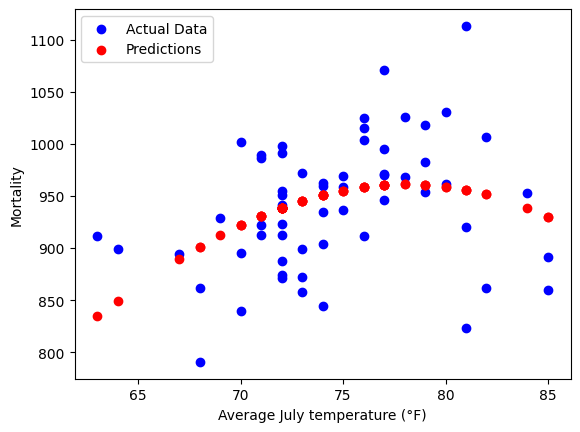

In [146]:
plt.scatter(X, y, color='blue', label='Actual Data')
plt.scatter(X, predictions, color='red', label="Predictions")

plt.xlabel("Average July temperature (°F)")
plt.ylabel("Mortality")
plt.legend()
plt.show()

In [147]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.5,
    random_state=1
)

print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))

Training observations: 30
Testing observations: 30


In [148]:
results = []

for degree in range(1,5):
    
    # Create polynomial variables
    poly = PolynomialFeatures(degree=degree, include_bias=False)
    
    # Fit polynomial transformation ONLY on training data
    X_train_poly = poly.fit_transform(X_train)
    
    # Apply the same transformation to test data
    X_test_poly = poly.transform(X_test)
    
    # Fit the regression model
    model = LinearRegression()
    model.fit(X_train_poly, y_train)
    
    # Predictions
    train_predictions = model.predict(X_train_poly)
    test_predictions = model.predict(X_test_poly)
    
    # Mean squared error
    train_mse = mean_squared_error(y_train, train_predictions)
    test_mse = mean_squared_error(y_test, test_predictions)
    
    # Store results
    results.append({
        "Degree": degree,
        "Training MSE": train_mse,
        "Testing MSE": test_mse
    })

results_df = pd.DataFrame(results)

results_df

,Degree,Training MSE,Testing MSE
0,1,2545.297540,5040.756601
1,2,1725.969873,6264.876170
2,3,1699.517207,5848.947351
3,4,1674.595113,5506.432933


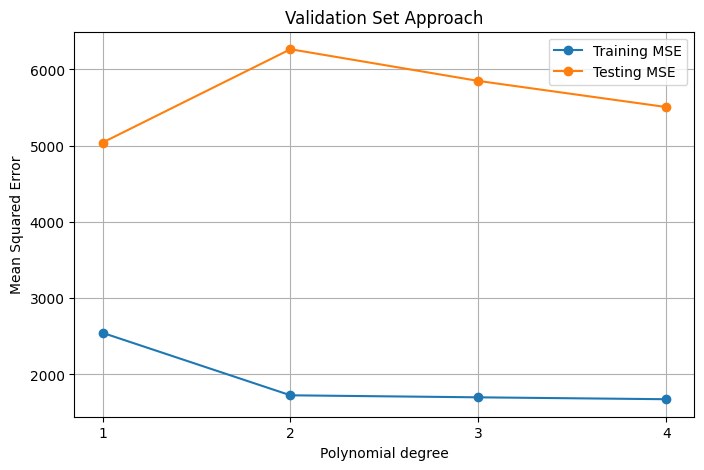

In [149]:
plt.figure(figsize=(8, 5))

plt.plot(
    results_df["Degree"],
    results_df["Training MSE"],
    marker="o",
    label="Training MSE"
)

plt.plot(
    results_df["Degree"],
    results_df["Testing MSE"],
    marker="o",
    label="Testing MSE"
)

plt.xlabel("Polynomial degree")
plt.ylabel("Mean Squared Error")
plt.title("Validation Set Approach")
plt.xticks(results_df["Degree"])
plt.legend()
plt.grid(True)

plt.show()

In [150]:
best_degree = results_df.loc[
    results_df["Testing MSE"].idxmin(),
    "Degree"
]

print("Degree with the lowest testing MSE:", best_degree)

Degree with the lowest testing MSE: 1


**Choice of degree of polynomial**

According to the figure, the smallest MSE for the testing data is found when using a first degree polynomial. The cell below will test if this finding holds when trying another random seed.

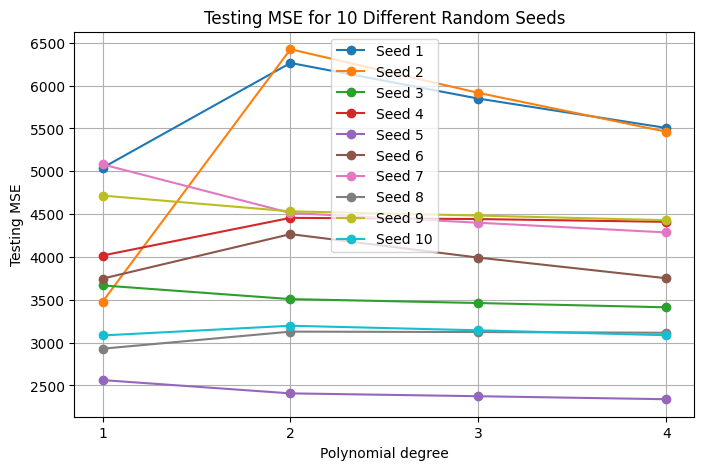

,Degree,Training MSE,Testing MSE
0,1,3488.978192,3832.598024
1,2,3000.735265,4270.324225
2,3,2968.855494,4118.939412
3,4,2937.189077,3980.173390


In [151]:
all_results = []

for seed in range(1, 11):
    
    # Split data using a new random seed
    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=0.5,
        random_state=seed
    )
    
    # Test polynomial degrees 1 to 4
    for degree in range(1, 5):
        
        # Create polynomial variables
        poly = PolynomialFeatures(
            degree=degree,
            include_bias=False
        )
        
        # Fit transformation on training data
        X_train_poly = poly.fit_transform(X_train)
        
        # Apply same transformation to test data
        X_test_poly = poly.transform(X_test)
        
        # Fit model
        model = LinearRegression()
        model.fit(X_train_poly, y_train)
        
        # Predictions
        train_predictions = model.predict(X_train_poly)
        test_predictions = model.predict(X_test_poly)
        
        # MSE
        train_mse = mean_squared_error(
            y_train,
            train_predictions
        )
        
        test_mse = mean_squared_error(
            y_test,
            test_predictions
        )
        
        # Store results
        all_results.append({
            "Seed": seed,
            "Degree": degree,
            "Training MSE": train_mse,
            "Testing MSE": test_mse
        })

all_results_df = pd.DataFrame(all_results)

plt.figure(figsize=(8, 5))

for seed in range(1, 11):
    
    seed_results = all_results_df[
        all_results_df["Seed"] == seed
    ]
    
    plt.plot(
        seed_results["Degree"],
        seed_results["Testing MSE"],
        marker="o",
        label=f"Seed {seed}"
    )

plt.xlabel("Polynomial degree")
plt.ylabel("Testing MSE")
plt.title("Testing MSE for 10 Different Random Seeds")
plt.xticks([1, 2, 3, 4])
plt.legend()
plt.grid(True)

plt.show()


average_results = all_results_df.groupby("Degree")[
    ["Training MSE", "Testing MSE"]
].mean().reset_index()

average_results

**Using different seeds for the selection of degree of polynomial**

This figure shows that the selection of training data points has a lot of influence on the MSE. The table shows that in general using a first degree polynomial is slightly better than a fourth polonomial. Using a second degree is in almost every case the worst idea. 

In [152]:
# Choose polynomial degree and number of folds
p = 2
k = 3

# Set up K-fold cross-validation
kf = KFold(n_splits=k, shuffle=True, random_state=42)

# Store results
fold_mse = []
fold_predictions = []
fold_actual = []

for train_index, test_index in kf.split(X):

    # Split into training and testing folds
    X_train, X_test = X.iloc[train_index], X.iloc[test_index]
    y_train, y_test = y.iloc[train_index], y.iloc[test_index]

    # Create polynomial features
    poly = PolynomialFeatures(degree=p, include_bias=False)
    X_train_poly = poly.fit_transform(X_train)
    X_test_poly = poly.transform(X_test)

    # Fit the model
    model = LinearRegression()
    model.fit(X_train_poly, y_train)

    # Predict on the held-out fold
    predictions = model.predict(X_test_poly)

    # Calculate MSE for this fold
    mse = mean_squared_error(y_test, predictions)
    fold_mse.append(mse)

    # Store predictions and actual values
    fold_predictions.extend(predictions)
    fold_actual.extend(y_test.to_numpy())

print("MSE for each fold:", fold_mse)
print("Mean cross-validation MSE:", np.mean(fold_mse))

MSE for each fold: [5427.166141037949, 3542.749041753369, 3799.6117609322405]
Mean cross-validation MSE: 4256.508981241187


In [153]:
prediction_variance = np.var(fold_predictions, ddof=1)

print("Variance of held-out predictions:", prediction_variance)

Variance of held-out predictions: 1670.881522149199


In [154]:
cv_results = []

for seed in range(1, 11):

    kf = KFold(n_splits=3, shuffle=True, random_state=seed)
    seed_mse = []
    seed_predictions = []

    for train_index, test_index in kf.split(X):

        X_train, X_test = X.iloc[train_index], X.iloc[test_index]
        y_train, y_test = y.iloc[train_index], y.iloc[test_index]

        poly = PolynomialFeatures(degree=2, include_bias=False)
        X_train_poly = poly.fit_transform(X_train)
        X_test_poly = poly.transform(X_test)

        model = LinearRegression()
        model.fit(X_train_poly, y_train)

        predictions = model.predict(X_test_poly)

        seed_mse.append(mean_squared_error(y_test, predictions))
        seed_predictions.extend(predictions)

    cv_results.append({
        "Seed": seed,
        "Mean CV MSE": np.mean(seed_mse),
        "Prediction variance": np.var(seed_predictions, ddof=1)
    })

cv_results_df = pd.DataFrame(cv_results)
cv_results_df

,Seed,Mean CV MSE,Prediction variance
0,1,5175.994078,2342.104145
1,2,5176.310229,2386.480103
2,3,3513.029877,680.639270
3,4,3826.803794,1215.940341
4,5,3924.199874,1450.176218
5,6,5740.597705,2682.531706
6,7,3758.749368,807.083828
7,8,3576.517064,767.715095
8,9,5723.806750,3441.812327
9,10,3658.313780,683.890793


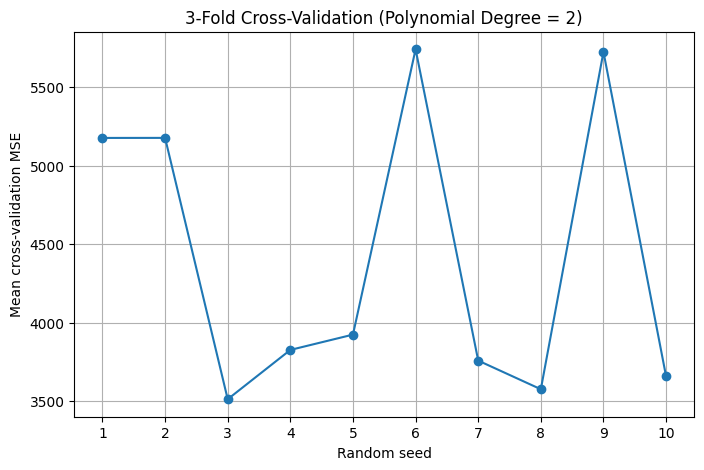

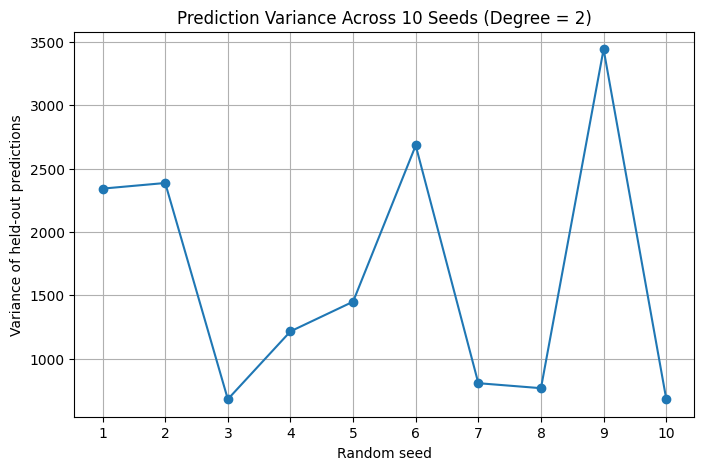

In [155]:
plt.figure(figsize=(8, 5))

plt.plot(
    cv_results_df["Seed"],
    cv_results_df["Mean CV MSE"],
    marker="o"
)

plt.xlabel("Random seed")
plt.ylabel("Mean cross-validation MSE")
plt.title("3-Fold Cross-Validation (Polynomial Degree = 2)")
plt.xticks(cv_results_df["Seed"])
plt.grid(True)
plt.show()


plt.figure(figsize=(8, 5))

plt.plot(
    cv_results_df["Seed"],
    cv_results_df["Prediction variance"],
    marker="o"
)

plt.xlabel("Random seed")
plt.ylabel("Variance of held-out predictions")
plt.title("Prediction Variance Across 10 Seeds (Degree = 2)")
plt.xticks(cv_results_df["Seed"])
plt.grid(True)
plt.show()

**K-fold cross-validation**

When the procedure is repeated 10 times, the results do not look to be similar at all. The means of the MSE values differ a lot between seeds and the variation as well. It would likely improve if the value for K was higher, since the average is taken over more groups, making it less variable. Since for each fold, the estimations would be based on a larger portion of the data

In [156]:
df2 = pd.read_csv(r"C:\Users\Gebruiker\OneDrive\Documenten\University\Lund\BERN02\bird_count.csv")

In [157]:
from scipy.optimize import minimize
import math

# Observed data
year_arr = np.array([1, 2, 3, 4, 6, 7, 8, 9, 10, 11, 12, 13, 14])
count_arr = np.array([10, 5, 9, 12, 14, 8, 12, 9, 5, 5, 5, 2, 12])

# Maximum-likelihood estimates from your earlier model
parameters = np.array([2.35777517, -0.03244319])

# Poisson log-likelihood
def log_likelihood(params, year, count):
    beta_0, beta_1 = params
    eta = beta_0 + beta_1 * year

    # Prevent numerical overflow
    if np.any(eta > 700):
        return -np.inf

    lam = np.exp(eta)

    return np.sum(
        -lam + count * eta
        - np.array([math.lgamma(int(c) + 1) for c in count])
    )

# Bootstrap standard error of the slope
rng = np.random.default_rng(123)

B = 2000
n = len(year_arr)
bootstrap_slopes = []

for b in range(B):
    # Resample year-count pairs with replacement
    indices = rng.choice(n, size=n, replace=True)

    year_boot = year_arr[indices]
    count_boot = count_arr[indices]

    boot_result = minimize(
        lambda params: -log_likelihood(
            params, year_boot, count_boot
        ),
        x0=parameters,
        method="BFGS"
    )

    if boot_result.success and np.all(np.isfinite(boot_result.x)):
        bootstrap_slopes.append(boot_result.x[1])

# Report results
bootstrap_slopes = np.array(bootstrap_slopes)

if len(bootstrap_slopes) > 1:
    bootstrap_se = np.std(bootstrap_slopes, ddof=1)
    print(f"Original slope estimate: {parameters[1]:.6f}")
    print(f"Bootstrap standard error: {bootstrap_se:.6f}")
else:
    print("Too few successful bootstrap fits. Check the optimization.")

Original slope estimate: -0.032443
Bootstrap standard error: 0.036274


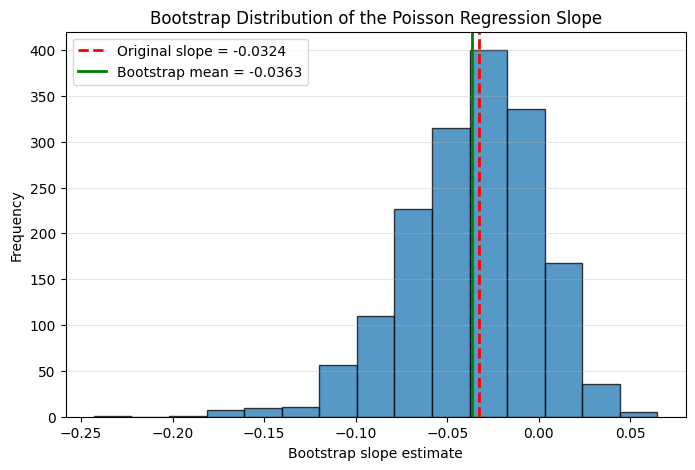

In [158]:

plt.figure(figsize=(8, 5))

plt.hist(
    bootstrap_slopes,
    bins=15,
    edgecolor="black",
    alpha=0.75
)

plt.axvline(
    parameters[1],
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"Original slope = {parameters[1]:.4f}"
)

plt.axvline(
    np.mean(bootstrap_slopes),
    color="green",
    linestyle="-",
    linewidth=2,
    label=f"Bootstrap mean = {np.mean(bootstrap_slopes):.4f}"
)

plt.xlabel("Bootstrap slope estimate")
plt.ylabel("Frequency")
plt.title("Bootstrap Distribution of the Poisson Regression Slope")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.show()


**standard deviation of the bootstrap sample of the slope parameter**

Bootstrap standard error: 0.036274